In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [2]:
data = pd.read_csv("StudentsPerformance.csv")

In [3]:
data.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [4]:
data.tail()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


In [5]:
data

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75
...,...,...,...,...,...,...,...,...
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77


In [6]:
data.nunique()

gender                          2
race/ethnicity                  5
parental level of education     6
lunch                           2
test preparation course         2
math score                     81
reading score                  72
writing score                  77
dtype: int64

In [7]:
data.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [8]:
data.dtypes

gender                         object
race/ethnicity                 object
parental level of education    object
lunch                          object
test preparation course        object
math score                      int64
reading score                   int64
writing score                   int64
dtype: object

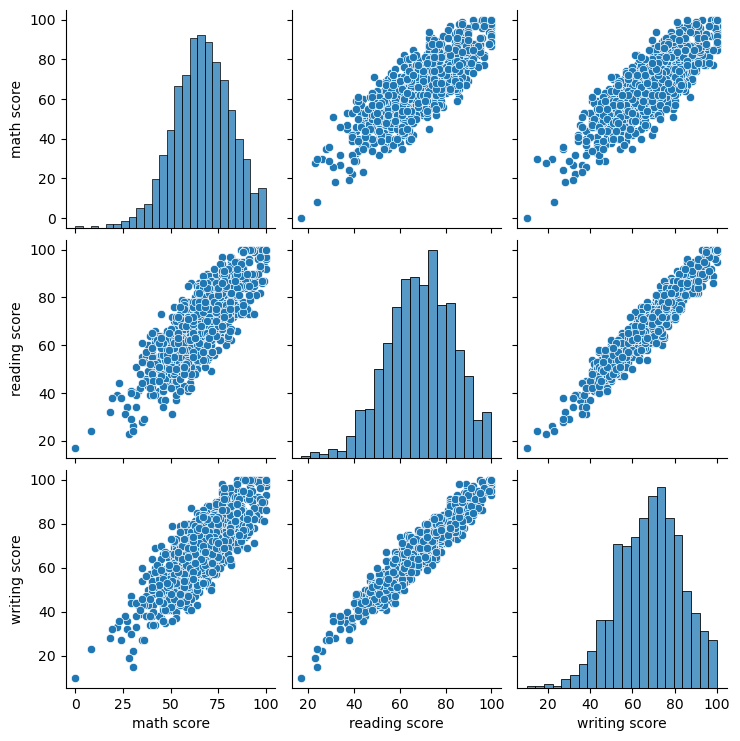

In [9]:
sns.pairplot(data)

In [10]:
student = data.drop(["race/ethnicity","parental level of education"],axis=1)

In [11]:
student

,gender,lunch,test preparation course,math score,reading score,writing score
0,female,standard,none,72,72,74
1,female,standard,completed,69,90,88
2,female,standard,none,90,95,93
3,male,free/reduced,none,47,57,44
4,male,standard,none,76,78,75
...,...,...,...,...,...,...
995,female,standard,completed,88,99,95
996,male,free/reduced,none,62,55,55
997,female,free/reduced,completed,59,71,65
998,female,standard,completed,68,78,77


In [12]:
student["gender"].unique()

array(['female', 'male'], dtype=object)

In [13]:
student["gender"] = student ["gender"].map({"female":0, "male":1})

In [14]:
student

,gender,lunch,test preparation course,math score,reading score,writing score
0,0,standard,none,72,72,74
1,0,standard,completed,69,90,88
2,0,standard,none,90,95,93
3,1,free/reduced,none,47,57,44
4,1,standard,none,76,78,75
...,...,...,...,...,...,...
995,0,standard,completed,88,99,95
996,1,free/reduced,none,62,55,55
997,0,free/reduced,completed,59,71,65
998,0,standard,completed,68,78,77


<Axes: xlabel='reading score', ylabel='math score'>

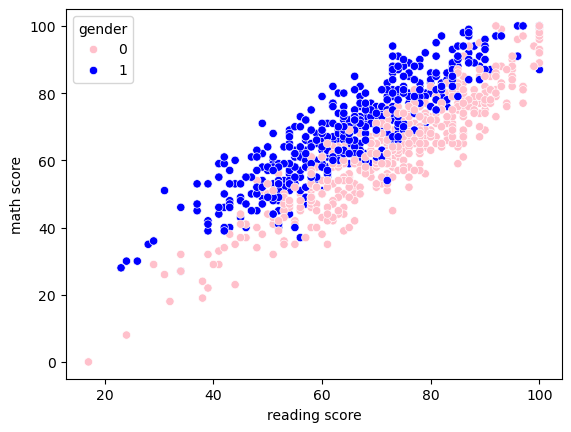

In [15]:
custom_color = {1:'blue',0:'pink'}
sns.scatterplot(x= "reading score" , y = "math score", hue = "gender" ,palette= custom_color, data=student)

<Axes: xlabel='math score', ylabel='Density'>

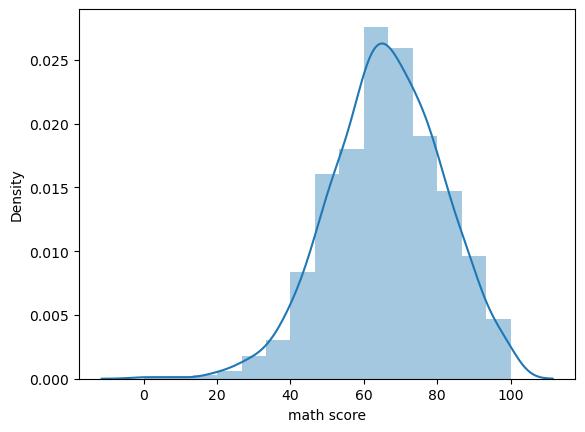

In [16]:
sns.distplot(student['math score'],bins = 15)

<Axes: xlabel='math score', ylabel='Density'>

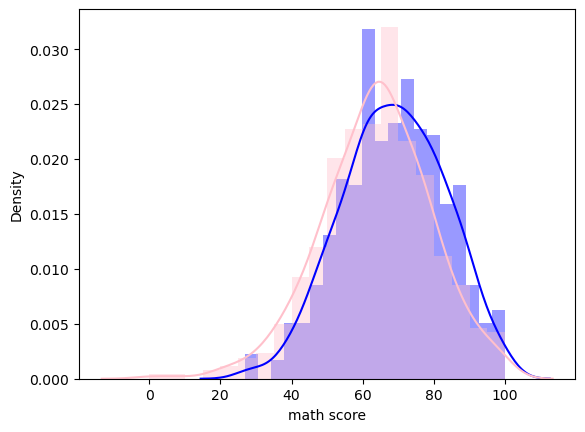

In [17]:
sns.distplot(student[student['gender'] == 1]['math score'],bins=20,color='blue', label = 'Male')
sns.distplot(student[student['gender'] == 0]['math score'],bins=20,color='pink', label = 'Female')

<Axes: xlabel='reading score', ylabel='Density'>

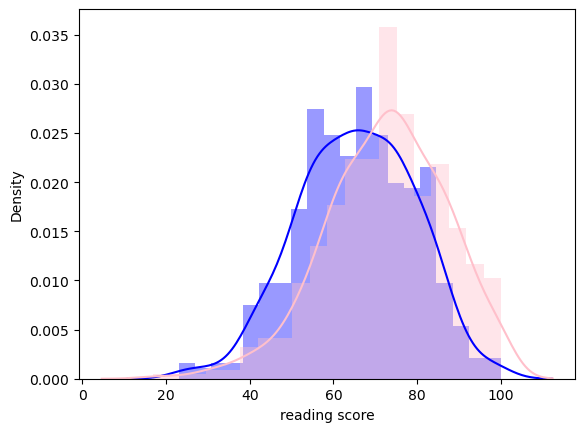

In [18]:
sns.distplot(student[student['gender'] == 1]['reading score'],bins=20,color='blue', label = 'Male')
sns.distplot(student[student['gender'] == 0]['reading score'],bins=20,color='pink', label = 'Female')

<Axes: xlabel='writing score', ylabel='Density'>

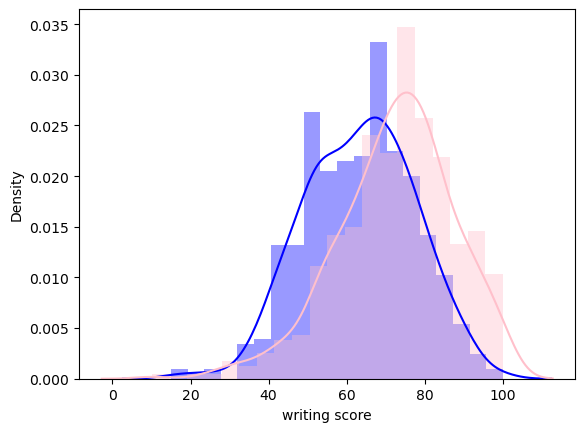

In [19]:
sns.distplot(student[student['gender'] == 1]['writing score'],bins=20,color='blue', label = 'Male')
sns.distplot(student[student['gender'] == 0]['writing score'],bins=20,color='pink', label = 'Female')

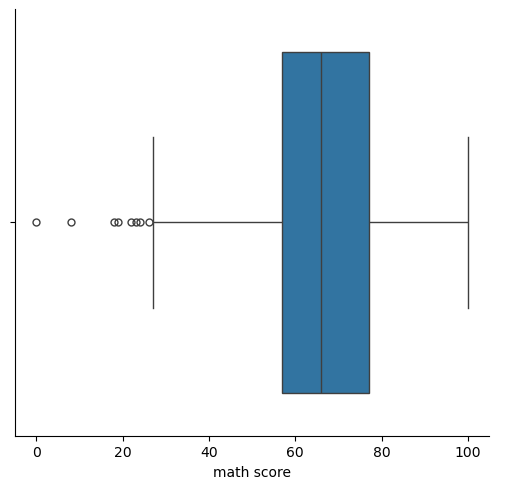

In [20]:
sns.catplot(x = 'math score', kind = 'box' , data = student)

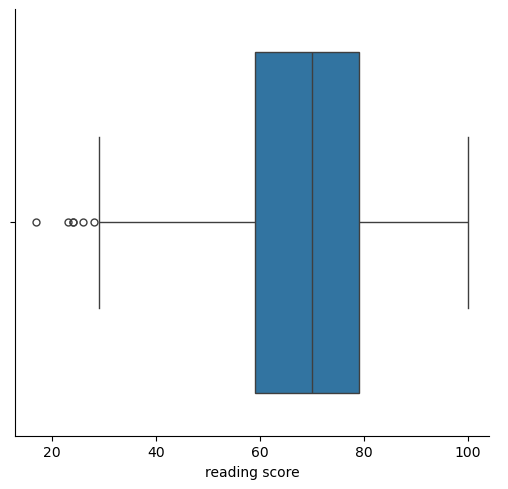

In [21]:
sns.catplot(x = 'reading score', kind = 'box' , data = student)

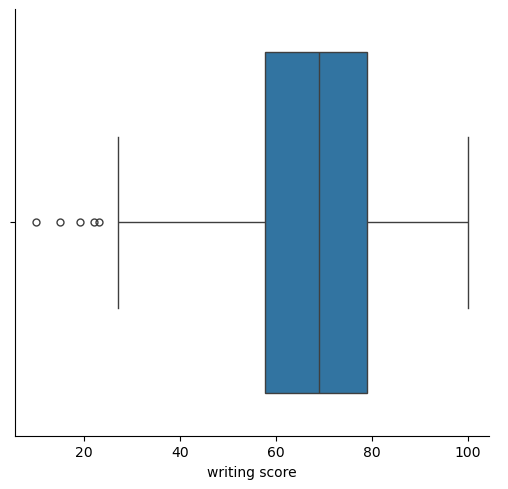

In [22]:
sns.catplot(x = 'writing score', kind = 'box' , data = student)

<Axes: >

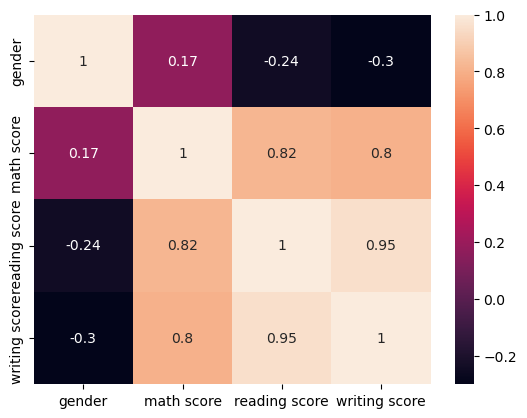

In [23]:
numerical_data = student.select_dtypes(include=['number'])
correlation = numerical_data.corr()
sns.heatmap(correlation, xticklabels = correlation.columns , yticklabels = correlation.columns, annot=True)
            

In [24]:
correlation = numerical_data.corr()

In [25]:
correlation

,gender,math score,reading score,writing score
gender,1.000000,0.167982,-0.244313,-0.301225
math score,0.167982,1.000000,0.817580,0.802642
reading score,-0.244313,0.817580,1.000000,0.954598
writing score,-0.301225,0.802642,0.954598,1.000000
